# 02 — Logistic regression: diagnosis and tuning (Soumaya)

Development set only (5-fold CV); the test set is not used.

**Scripts run, this notebook explains.** Every number here is produced by
`tuning/logistic_regression.py` and saved in `tuning/results/logistic_regression/`;
this notebook only reads those files and comments on them (no training here).

| Step | Command (from the project root) | Output |
|---|---|---|
| 1-2. Baseline + diagnosis | `python3 -m tuning.logistic_regression baseline` | `baseline.csv` |
| 3. Validation curves | `python3 -m tuning.logistic_regression curves` | `curves.csv`, `curves/*.png` |
| 4. Elastic Net + Lasso zeros | `python3 -m tuning.logistic_regression lasso` | `elastic_net.csv`, `lasso_*.csv`, `lasso/*.png` |
| 5. Interactions | `python3 -m tuning.logistic_regression interactions` | `interactions.csv`, `interactions_folds.csv`, `interactions.png` |
| 6. Tuning v2 | `python3 -m tuning.tune --version v2 --model lr`, then `python3 -m tuning.logistic_regression baseline` | `tuning/results/v2/best_params.json`, `baseline.csv` |
| 7. Optional: grid vs random vs Optuna | `python3 -m tuning.logistic_regression search` | `search.csv`, `search_trials.csv`, `search.png` |

Tuning v1 = Soumaya's first Optuna run: `tuning/results/v1/best_params.json`
(git tag `baseline-v1`): C = 5.18, L2, no class weights.

Metrics (always mean ± standard deviation over the 5 folds): **PR-AUC** (main
metric; 0.239 = the share of high earners = the floor), **ROC-AUC**, **Brier**
(quality of the probabilities, lower is better).

Hyperparameters studied: `C` (regularization strength, C = 1/λ), the penalty
(L1 / L2 / Elastic Net through `l1_ratio`), `class_weight`; plus three
interaction columns.

Course sessions used: **S2** logistic regression and L1 / L2 / Elastic Net
regularization; **S5** Pipeline, cross-validation, validation curves,
bias–variance, grid / random / Optuna search; **S6** PR-AUC and class weights;
**S7** Brier score and calibration.

In [1]:
import sys
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))
RESULTS = ROOT / "tuning" / "results" / "logistic_regression"
COLS = ["train PR-AUC", "val PR-AUC", "val PR-AUC std", "gap PR-AUC",
        "val ROC-AUC", "val ROC-AUC std", "val Brier", "val Brier std"]

## 1. Baseline

**How a logistic regression "minimises the loss" (S2).** It gives each column a
weight, adds the weighted columns up and turns the sum into a probability with
the sigmoid. Training looks for the weights that minimise **one global loss** on
the training folds:

> C × (log-loss summed over the ~31,200 training rows) + penalty on the weights

- the **log-loss** measures how surprised the model is by the true labels. The
  model is trained on exactly this, which is why its probabilities are usually
  good (S7);
- the **penalty** is the regularization: **L2** (ridge) = sum of the squared
  weights, shrinks every weight a little; **L1** (lasso) = sum of the absolute
  weights, can set weights to exactly 0; **Elastic Net** = a mix of the two;
- **C = 1/λ**: a small C is a large λ, a strong penalty, small weights, a
  simpler model (more bias). A large C is almost no penalty: the model is close
  to the unpenalised fit (more variance).

The model is **linear in its columns**: it cannot build a curve or an
interaction by itself. That is why `age_squared`, `is_married`, `has_degree`,
`part_time` and `overtime` are created in the Pipeline (F12), and why section 5
tests interactions.

Four starting points, from the floor to the tuned v1 model (5-fold CV):

In [2]:
baseline = pd.read_csv(RESULTS / "baseline.csv")
baseline[["experiment", *COLS]].round(4)

,experiment,train PR-AUC,val PR-AUC,val PR-AUC std,gap PR-AUC,val ROC-AUC,val ROC-AUC std,val Brier,val Brier std
0,Dummy (predicts the base rate),0.2394,0.2394,0.0000,-0.0000,0.5000,0.0000,0.1821,0.0000
1,"LR defaults, 6 inputs only (C=1, L2)",0.6889,0.6880,0.0107,0.0009,0.8826,0.0051,0.1144,0.0022
2,"LR defaults + engineered features (C=1, L2)",0.7096,0.7082,0.0128,0.0014,0.8888,0.0056,0.1113,0.0026
3,"LR tuned v1 (C=5.18, L2)",0.7097,0.7083,0.0129,0.0014,0.8887,0.0056,0.1113,0.0027
4,LR tuned v2,0.7097,0.7083,0.0129,0.0014,0.8887,0.0057,0.1113,0.0027


PR-AUC: higher is better; 0.239 is the floor (the share of high earners).
Brier: quality of the probabilities, lower is better (0.182 = always predicting
the base rate).

## 2. Diagnosis: train vs validation (overfitting or underfitting?)

1. **No overfitting.** Tuned v1: train 0.7097, validation 0.7083, so the gap is
   0.0014, about ten times smaller than the fold-to-fold noise (± 0.013). The
   random forest needed strong limits on its trees to bring its gap down to 0.04
   (F36); the logistic regression starts there. With 37 columns and about 31,200
   rows per training fold, there is almost nothing to memorise.
2. **So it is underfitting (bias), not variance.** The model reaches only 0.710
   even on the rows it learned from. A small gap with a mediocre score is the
   S5 signature of **high bias**: the model is too simple for part of the
   pattern in the data. The flexible models do a little better on the same
   folds: random forest v2 0.715 (train 0.754), LightGBM v1 0.719 (F19, F36).
   About 0.007-0.011 PR-AUC is therefore the cost of being linear; the rest of
   the distance to 1 is the limit of the 6 inputs (the ceiling, F36).
3. **Tuning v1 changed nothing:** default C = 1 gives 0.7082, tuned C = 5.18
   gives 0.7083; Brier 0.1113 for both.
4. **Feature engineering did what tuning could not:** 0.688 → 0.708 (+0.020)
   with the 5 engineered columns. That is the right remedy for bias: give the
   model more expressive inputs. Regularization can only *add* bias (it shrinks
   the weights), so it cannot fix underfitting.
5. **The probabilities are already good:** validation Brier 0.111, the level of
   random forest v2 (0.110) and LightGBM (0.111), without recalibration (F22:
   ECE 0.006).

**Answer: underfitting (high bias, very low variance).** Prediction for the next
steps: changing C can only do nothing or hurt; only new information (an
interaction) can help, and only a little.

## 3. Validation curves on the key hyperparameters

One setting changes, the others stay at the sklearn defaults (C = 1, L2, no
class weights), with the solver used by the tuning (`liblinear`, as in
`src/models.py`). C goes from 0.0001 to 100 on a log scale, two points per
decade, **separately for L2 and L1**. The table shows λ = 1/C next to C.

C_L2


,value,lambda = 1/C,train PR-AUC,val PR-AUC,val PR-AUC std,gap PR-AUC,val ROC-AUC,val ROC-AUC std,val Brier,val Brier std,not converged
0,0.0001,10000.0000,0.5811,0.5815,0.0116,-0.0004,0.8382,0.0054,0.1616,0.0010,0
1,0.0003,3333.3333,0.6274,0.6276,0.0112,-0.0002,0.8598,0.0051,0.1378,0.0013,0
2,0.001,1000.0000,0.6645,0.6643,0.0114,0.0003,0.8743,0.0050,0.1230,0.0016,0
3,0.003,333.3333,0.6858,0.6852,0.0113,0.0006,0.8812,0.0052,0.1166,0.0019,0
4,0.01,100.0000,0.6993,0.6982,0.0116,0.0010,0.8854,0.0054,0.1134,0.0022,0
5,0.03,33.3333,0.7057,0.7045,0.0122,0.0012,0.8875,0.0055,0.1121,0.0024,0
6,0.1,10.0000,0.7086,0.7073,0.0125,0.0013,0.8886,0.0055,0.1115,0.0025,0
7,0.3,3.3333,0.7094,0.7080,0.0127,0.0014,0.8888,0.0055,0.1114,0.0026,0
8,1,1.0000,0.7096,0.7083,0.0128,0.0014,0.8888,0.0056,0.1113,0.0026,0
9,3,0.3333,0.7097,0.7083,0.0129,0.0014,0.8888,0.0056,0.1113,0.0027,0


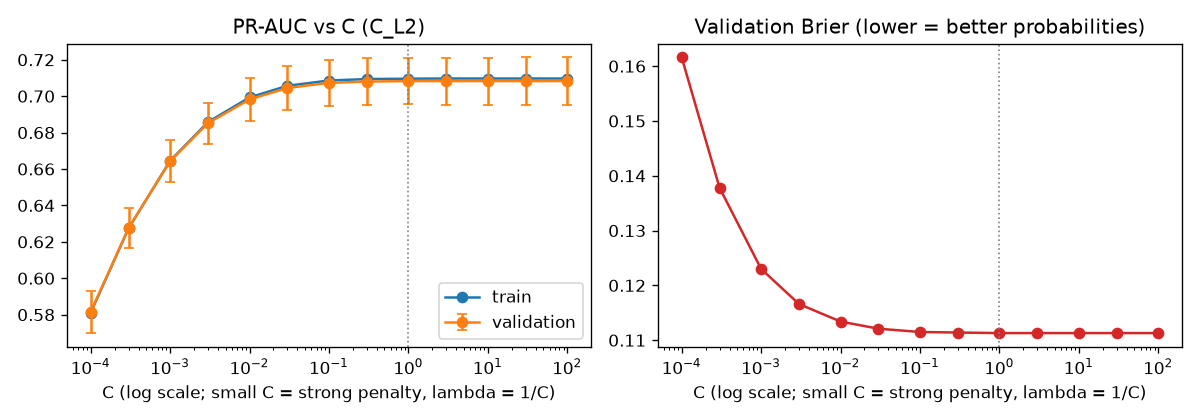

C_L1


,value,lambda = 1/C,train PR-AUC,val PR-AUC,val PR-AUC std,gap PR-AUC,val ROC-AUC,val ROC-AUC std,val Brier,val Brier std,not converged
13,0.0001,10000.0000,0.2394,0.2394,0.0000,-0.0000,0.5000,0.0000,0.2500,0.0000,0
14,0.0003,3333.3333,0.4362,0.4364,0.0070,-0.0002,0.7150,0.0076,0.1848,0.0002,0
15,0.001,1000.0000,0.6423,0.6425,0.0100,-0.0002,0.8610,0.0063,0.1338,0.0013,0
16,0.003,333.3333,0.6578,0.6578,0.0128,-0.0000,0.8723,0.0059,0.1212,0.0020,0
17,0.01,100.0000,0.6826,0.6819,0.0116,0.0007,0.8795,0.0056,0.1163,0.0021,0
18,0.03,33.3333,0.7044,0.7032,0.0123,0.0012,0.8871,0.0056,0.1123,0.0024,0
19,0.1,10.0000,0.7088,0.7075,0.0127,0.0013,0.8886,0.0056,0.1114,0.0026,0
20,0.3,3.3333,0.7095,0.7081,0.0128,0.0014,0.8888,0.0056,0.1113,0.0026,0
21,1,1.0000,0.7097,0.7083,0.0129,0.0014,0.8888,0.0056,0.1113,0.0027,0
22,3,0.3333,0.7097,0.7083,0.0129,0.0014,0.8887,0.0057,0.1113,0.0027,0


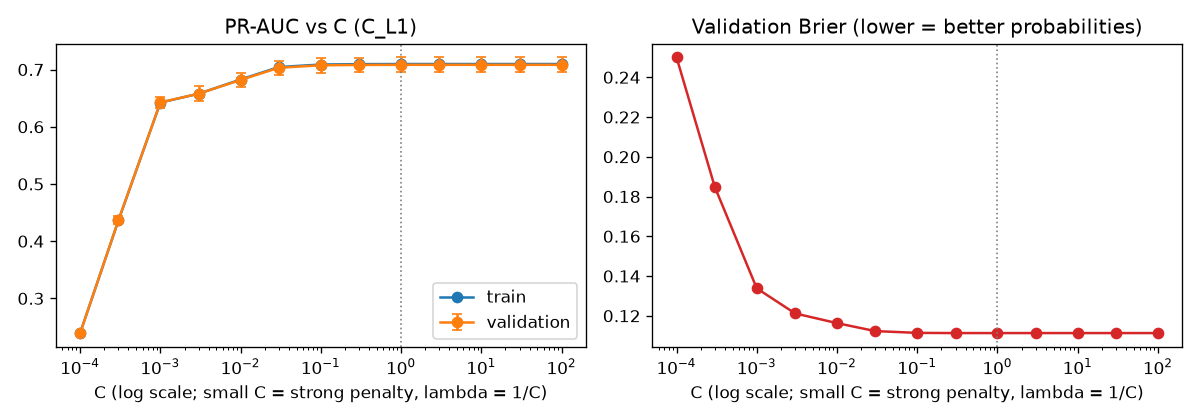

class_weight


,value,lambda = 1/C,train PR-AUC,val PR-AUC,val PR-AUC std,gap PR-AUC,val ROC-AUC,val ROC-AUC std,val Brier,val Brier std,not converged
26,None,NaN,0.7096,0.7083,0.0128,0.0014,0.8888,0.0056,0.1113,0.0026,0
27,balanced,NaN,0.7074,0.7063,0.0128,0.0011,0.8886,0.0055,0.1397,0.0028,0


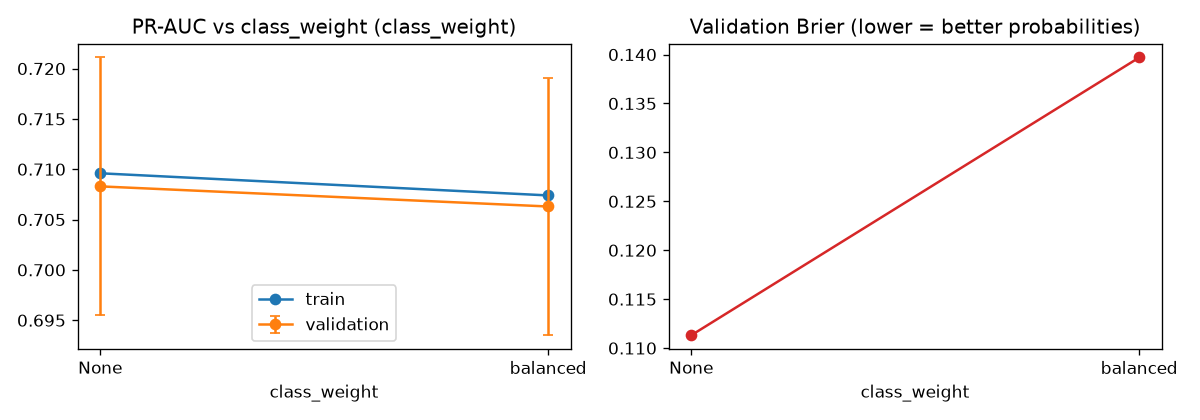

In [3]:
curves = pd.read_csv(RESULTS / "curves.csv")
curves["value"] = curves["value"].fillna("None")  # pandas reads the text "None" as missing
for name, table in curves.groupby("curve", sort=False):
    print(name)
    display(table[["value", "lambda = 1/C", *COLS, "not converged"]].round(4))
    display(Image(str(RESULTS / "curves" / f"{name}.png")))

### What the curves show

| Curve | Best validation PR-AUC | What the curve shows | Decision for v2 |
|---|---|---|---|
| `C`, L2 | 0.7083 (C = 1 to 100) | Flat from C = 0.3 (0.7080); within 0.001 of the best from C = 0.1 (0.7073). A strong penalty underfits: C = 0.01 → 0.698, C = 0.0001 → 0.582. Train and validation fall **together**: the gap stays ≤ 0.0015 on the whole curve | Search C from 0.01 to 100 (log) |
| `C`, L1 | 0.7083 (C = 1 to 100) | Same plateau (0.7075 at C = 0.1). Falls faster than L2 when C is small: at C = 0.0001 every weight is 0 and the model is the Dummy (0.239) | L1 = L2 on the plateau |
| `class_weight` | 0.7083 at None | balanced: 0.7063, and Brier 0.111 → 0.140 (every probability pushed up) | Fix at None |

**Key reading.**
- **The right half of each curve is flat and the gap never opens**, even at
  C = 100 (almost no penalty): there is no variance to remove, so
  regularization has nothing to fix. This confirms section 2.
- **The left half is pure underfitting** (S5 bias–variance): when λ = 1/C is
  large, the weights are squeezed towards 0 and train and validation drop
  together.
- **Why is it so flat?** C multiplies the *sum* of the log-losses over about
  31,200 rows. Next to that sum, even C = 0.1 (λ = 10) is a weak penalty; it
  only bites below about C = 0.03.
- **Brier 0.250 at C = 0.0001 with L1**, worse than the Dummy (0.182): the
  `liblinear` solver also penalises the intercept, so when every weight is
  squeezed to 0 the model predicts 0.5 for everyone instead of the base rate.
- **`class_weight` confirms F16 in isolation:** re-weighting does not help the
  ranking and damages the probabilities (S6, S7).

## 4. Elastic Net and Lasso: which columns does L1 set to exactly 0?

Two runs (`python3 -m tuning.logistic_regression lasso`):

1. **Lasso path:** pure L1 with `liblinear` (as in the curves), 25 values of C
   from 0.0001 to 100 (4 per decade). For each C and each of the 37 columns
   after preprocessing, we count in how many of the 5 training folds the weight
   is **exactly 0**.
2. **Elastic Net:** `l1_ratio` = 0 (pure L2), 0.25, 0.5, 0.75, 1 (pure L1), each
   with 7 values of C. Penalty = l1_ratio × L1 + (1 − l1_ratio) × L2. Elastic
   Net needs the `saga` solver (`liblinear` only does pure L1 or pure L2).

**Why L1 gives exact zeros and L2 does not (S2).** The L2 penalty grows like
w², so its pull towards 0 fades as a weight gets small: weights shrink but stay
non-zero. The L1 penalty grows like |w|: it pulls with the same strength however
small the weight is, so a column whose contribution to the loss is smaller than
that pull is switched off completely. Lasso is therefore also a feature
selector.

Lasso (L1, liblinear): number of non-zero weights and validation scores


,C,non-zero weights (mean of folds),val PR-AUC,val PR-AUC std,gap PR-AUC,val Brier
0,0.0001,0.0,0.2394,0.0000,-0.0000,0.2500
1,0.0002,0.0,0.2394,0.0000,-0.0000,0.2145
2,0.0003,1.0,0.4364,0.0070,-0.0002,0.1824
3,0.0006,4.0,0.5781,0.0052,-0.0004,0.1536
4,0.0010,6.0,0.6425,0.0100,-0.0002,0.1338
5,0.0018,6.0,0.6533,0.0120,-0.0002,0.1246
6,0.0032,7.0,0.6585,0.0128,0.0000,0.1209
7,0.0056,10.4,0.6700,0.0128,0.0005,0.1184
8,0.0100,12.4,0.6819,0.0116,0.0007,0.1163
9,0.0178,21.0,0.6969,0.0123,0.0009,0.1137


Per column: zero in all 5 folds for every C up to this value (smallest = strongest)


,column,zero in all folds for every C up to,"folds at zero, C = 1","folds at zero, C = 100","mean weight, C = 1"
0,education-num,0.0002,0,0,0.7074
1,age,0.0003,0,0,2.8459
2,hours-per-week,0.0003,0,0,-0.0279
3,marital-status_Never-married,0.0003,0,0,-0.3815
4,marital-status_Married-civ-spouse,0.0006,0,0,1.0569
5,is_married,0.0006,0,0,0.9065
6,occupation_Exec-managerial,0.0018,0,0,0.7890
7,occupation_Other-service,0.0032,0,0,-0.8657
8,part_time,0.0032,0,0,-0.8729
9,overtime,0.0032,0,0,0.5201


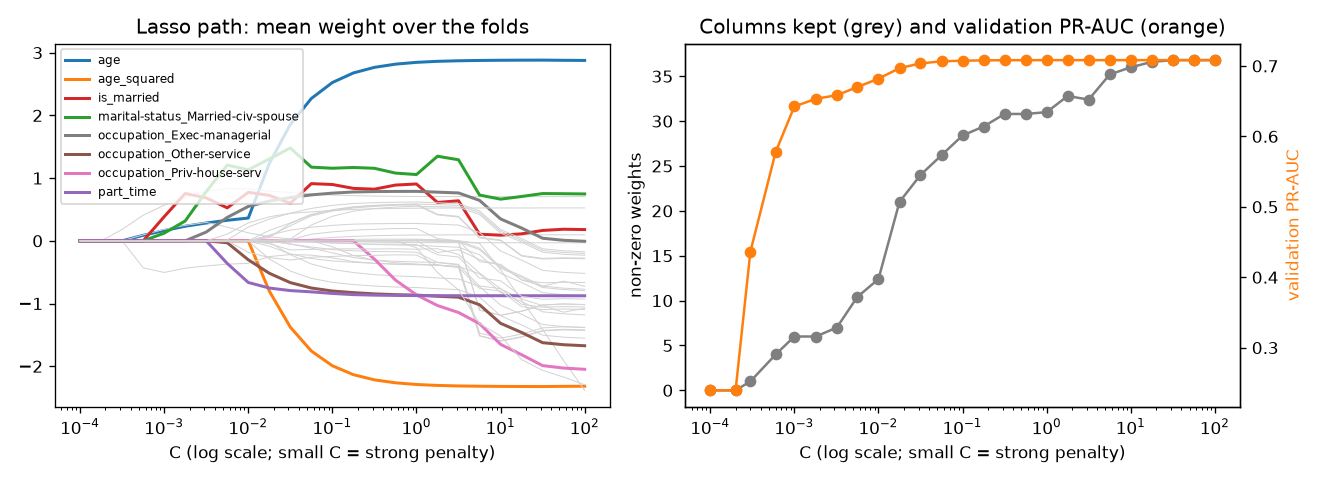

In [4]:
zeros = pd.read_csv(RESULTS / "lasso_zeros.csv")
lasso = pd.read_csv(RESULTS / "lasso_scores.csv")
print("Lasso (L1, liblinear): number of non-zero weights and validation scores")
display(lasso[["C", "non-zero weights (mean of folds)", "val PR-AUC", "val PR-AUC std",
               "gap PR-AUC", "val Brier"]].round(4))
print("Per column: zero in all 5 folds for every C up to this value (smallest = strongest)")
display(zeros.round(4))
display(Image(str(RESULTS / "lasso" / "lasso_path.png")))

Elastic Net (saga): validation PR-AUC by l1_ratio (rows) and C (columns)


C,0.0001,0.0010,0.0100,0.1000,1.0000,10.0000,100.0000
l1_ratio,,,,,,,
0.00,0.6346,0.6734,0.6983,0.7073,0.7082,0.7083,0.7083
0.25,0.5944,0.6600,0.6960,0.7074,0.7083,0.7083,0.7083
0.50,0.2394,0.6527,0.6923,0.7074,0.7083,0.7083,0.7083
0.75,0.2394,0.6543,0.6876,0.7074,0.7083,0.7083,0.7083
1.00,0.2394,0.6560,0.6817,0.7075,0.7083,0.7083,0.7083


Weights set to exactly 0 (mean of the 5 folds)


C,0.0001,0.0010,0.0100,0.1000,1.0000,10.0000,100.0000
l1_ratio,,,,,,,
0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0
0.25,32.0,26.4,9.2,4.0,2.2,0.4,0.0
0.50,37.0,30.4,14.0,5.8,3.4,1.6,0.0
0.75,37.0,32.0,19.4,7.0,3.6,2.2,0.0
1.00,37.0,32.0,24.0,8.4,4.4,2.6,1.0


Folds where saga did not converge: 0


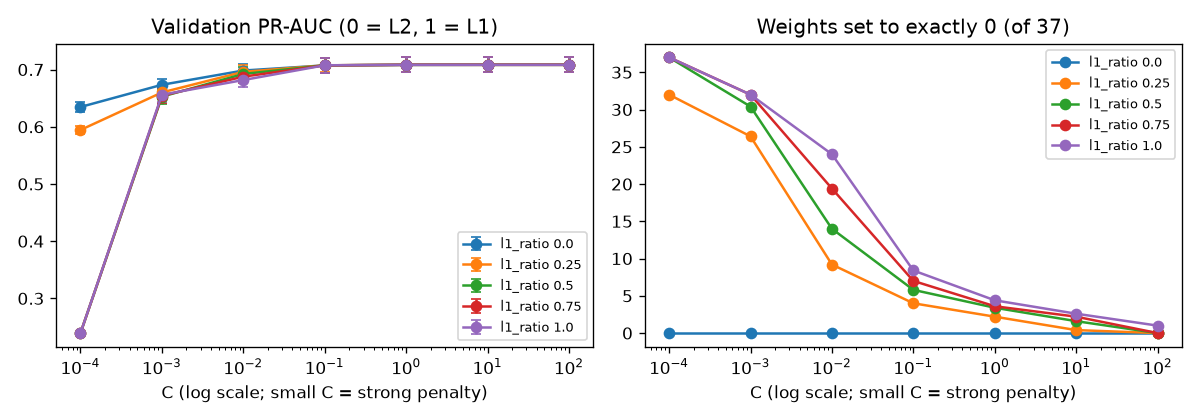

In [5]:
en = pd.read_csv(RESULTS / "elastic_net.csv")
print("Elastic Net (saga): validation PR-AUC by l1_ratio (rows) and C (columns)")
display(en.pivot(index="l1_ratio", columns="C", values="val PR-AUC").round(4))
print("Weights set to exactly 0 (mean of the 5 folds)")
display(en.pivot(index="l1_ratio", columns="C", values="zero weights (mean of folds)"))
print("Folds where saga did not converge:", int(en["not converged"].sum()))
display(Image(str(RESULTS / "lasso" / "elastic_net.png")))

### Which columns does Lasso set to exactly 0, and from which C?

From `lasso_scores.csv` and `lasso_path.csv` (L1, `liblinear`):

| C (λ = 1/C) | Columns kept, of 37 (mean of folds) | Val PR-AUC | Columns at 0 in all 5 folds |
|---|---|---|---|
| 0.0001 (10,000) | 0 | 0.239 | all: the model is the Dummy |
| 0.0003 (3,162) | 1 | 0.436 | all but `education-num` |
| 0.001 (1,000) | 6 | 0.6425 | all but education-num, age, hours-per-week, Never-married, Married-civ-spouse, is_married |
| 0.01 (100) | 12.4 | 0.682 | 23 columns |
| 0.03 (32) | 24.0 | 0.704 | 10: Married-spouse-absent, Separated, Widowed, Adm-clerical, Craft-repair, occupation Never-worked, Priv-house-serv, Transport-moving, Local-gov, No-pay |
| 0.1 (10) | 28.4 | 0.7075 | 6: Married-spouse-absent, Widowed, Adm-clerical, occupation Never-worked, Priv-house-serv, No-pay |
| 1 (1) | 31.0 | 0.7083 | 2: occupation Never-worked (8 people) and `workclass_Unknown` (a copy of `occupation_Unknown`, see below). At 0 in 4 of 5 folds: No-pay, Married-spouse-absent, Widowed, Adm-clerical; in 3 of 5: Local-gov |
| 100 (0.01) | 36.8 | 0.7083 | none (occupation Never-worked at 0 in 1 fold) |

**Reading.**
- **The order in which the columns enter is the EDA ranking (F9):** education
  first, then age, hours and marital status, then occupation and the hours
  regimes (`lasso_zeros.csv`). Lasso finds the strongest signals by itself.
- **Rare or weak categories go first.** In the development set: occupation
  Never-worked 8 people, No-pay 22, Priv-house-serv 184, Married-spouse-absent
  488; Widowed (1,209 people) is not rare but weak (weight 0.01 at C = 1). A
  column that concerns few people adds little to the total log-loss, so the L1
  pull wins sooner. A weight of 0 for a category means the model gives that
  group no correction of its own; it does not mean the group is ignored.
- **About 9 columns can go for almost nothing:** at C = 0.1 the model keeps 28
  of 37 columns and loses 0.0008 PR-AUC (0.7075 vs 0.7083). On the plateau
  (C ≥ 1) Lasso keeps almost everything, because there is no overfitting to
  fight.
- **Two pairs of columns are exact copies.** `is_married` = the one-hot
  `Married-civ-spouse` (after the EDA merge, F34), and `workclass_Unknown` =
  `occupation_Unknown` (both are missing for the same 2,242 people, F2). With
  two identical columns, |a| + |b| is the same however the weight is split, so
  the L1 penalty cannot tell the solutions apart and the choice is arbitrary
  (S2: Lasso picks one of several correlated columns). Here it keeps both
  married columns (0.91 and 1.06 at C = 1) but puts `workclass_Unknown` at 0
  and gives the weight to `occupation_Unknown` (−0.13). Harmless for the
  predictions (the model uses the sum), but these weights must not be read one
  by one.
- **Why the script fixes `random_state`:** `liblinear` shuffles the data. In two
  earlier runs without a seed, the scores were identical to 4 decimals, but the
  zeros on these weak or duplicate columns moved (at C = 1, Local-gov was at 0
  in 4 folds in one run and in 2 in the other). With `random_state=42` two runs
  give identical files. So **the zeros of weak columns are not a stable
  "feature selection"; the order of the strong columns is.**
- **On the left panel, some weights keep moving after C ≈ 3 while the score
  does not change at all** (e.g. the two married columns trade weight). Every
  category of a variable is one-hot encoded and there is an intercept, so the
  same predictions can be written with different weights; when the penalty is
  weak, almost nothing pins them down. Read the weights at one C (here C = 1),
  not their drift.
- **Elastic Net never beats pure L2.** On the plateau (C ≥ 1) every l1_ratio
  gives 0.7083. Under a strong penalty, the more L1 the worse: at C = 0.01,
  0.698 (L2) → 0.696 → 0.692 → 0.688 → 0.682 (L1), because L1 removes columns
  that L2 would only shrink. The mix helps when there are many correlated or
  useless columns and some overfitting; here there are 37 columns, almost all
  with some signal, and no overfitting. **Decision: no Elastic Net in v2.**
- **Solver check:** `saga` with l1_ratio 0 and `liblinear` L2 agree on the
  plateau (0.708) and at C = 0.01 (0.698). They differ only under a very strong
  penalty (C = 0.0001: 0.635 vs 0.582) because `liblinear` also penalises the
  intercept: fully squeezed, the `saga` model predicts the base rate (Brier
  0.182, like the Dummy) and the `liblinear` one predicts 0.5 (Brier 0.250).
  No convergence problem in any run (0 folds not converged).

## 5. Interactions, one at a time

A linear model can only use an interaction if it is given as a column (S2).
Trees build interactions by themselves (S3-S4), which is why the engineered
features helped only the logistic regression (F15). Three candidates, each the
product of two columns, created inside the Pipeline (imputed and scaled on the
training folds only, so no leakage):

- `education x hours` = education-num × hours-per-week
- `age x education` = age × education-num
- `married x hours` = is_married × hours-per-week (lets the effect of the
  working hours differ between married and unmarried people)

**Rule fixed before the run** (written in `tuning/logistic_regression.py`
before any interaction was scored): an interaction **helps** only if it adds
**at least +0.001 mean validation PR-AUC** *and* is **better in at least 4 of
the 5 folds**. Reference: tuned v1 without interaction, on the same folds.
Each interaction is added alone; only those that pass are kept.

**Why compare fold by fold (paired)?** The fold standard deviation (± 0.013) is
mostly "some folds are harder than others", and that affects both models the
same way. Comparing on the same fold removes that shared part, so a small but
consistent gain becomes visible (S5 cross-validation).

,experiment,val PR-AUC,val PR-AUC std,gap PR-AUC,val ROC-AUC,val Brier,gain PR-AUC,folds better,gain ROC-AUC,change Brier,weight (scaled),passes rule
0,reference: LR tuned v1,0.7083,0.0129,0.0014,0.8887,0.1113,NaN,NaN,NaN,NaN,NaN,NaN
1,education x hours,0.7086,0.0131,0.0015,0.8887,0.1114,0.0003,4.0,-0.0000,0.0000,-0.186,False
2,age x education,0.7083,0.0129,0.0014,0.8887,0.1113,-0.0000,3.0,-0.0000,0.0000,-0.001,False
3,married x hours,0.7099,0.0129,0.0014,0.8894,0.1110,0.0016,5.0,0.0006,-0.0003,-0.697,True


Validation PR-AUC per fold


,fold,reference,education x hours,age x education,married x hours
0,1,0.7096,0.7101,0.7096,0.7115
1,2,0.7055,0.7056,0.7056,0.7075
2,3,0.6882,0.6882,0.6883,0.6902
3,4,0.7289,0.7292,0.7287,0.7309
4,5,0.7092,0.7098,0.7092,0.7095


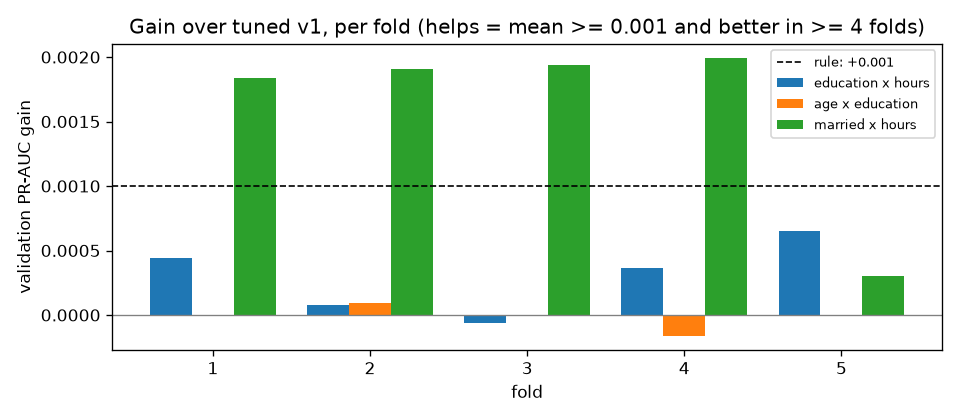

In [6]:
inter = pd.read_csv(RESULTS / "interactions.csv")
display(inter[["experiment", "val PR-AUC", "val PR-AUC std", "gap PR-AUC", "val ROC-AUC",
               "val Brier", "gain PR-AUC", "folds better", "gain ROC-AUC", "change Brier",
               "weight (scaled)", "passes rule"]].round(4))
print("Validation PR-AUC per fold")
display(pd.read_csv(RESULTS / "interactions_folds.csv").round(4))
display(Image(str(RESULTS / "interactions.png")))

| Interaction | Gain in PR-AUC | Folds better | Passes the rule? |
|---|---|---|---|
| `education x hours` | +0.0003 | 4 of 5 | No: consistent but below +0.001 |
| `age x education` | 0.0000 | 3 of 5 | No |
| `married x hours` | **+0.0016** | **5 of 5** | **Yes: kept** |

- **`married x hours` is the only one kept.** Validation 0.7083 → 0.7099,
  better in every fold (by about +0.0003 to +0.0020), ROC-AUC +0.0006, Brier
  0.1113 → 0.1110, gap unchanged (0.0014). Its weight is negative (−0.70 on the
  scaled column): each extra hour of work raises the log-odds of a high income
  *less* for married people than for unmarried people. Without it, the model is
  forced to use one hours slope for both groups.
- **`education x hours`** is consistent (4 of 5 folds) but too small
  (+0.0003): `has_degree`, `part_time` and `overtime` already carry most of it.
  **`age x education`** adds nothing.
- **Size:** +0.0016 is consistent but small, about an eighth of the fold
  standard deviation. It does not change section 2: the logistic regression
  stays below the random forest (0.715).
- **Caveat:** three candidates were tried on the same folds, so the kept one is
  slightly optimistic (S5); the "4 of 5 folds" part of the rule protects against
  a gain that comes from one lucky fold. The test set gives the honest number.
- **Fairness caution:** marriage is the strongest proxy for sex in these data
  (F30, F31). This interaction gives the model a finer use of that proxy, so if
  it is adopted, the equalized-odds gap by sex must be re-checked (S9).

## 6. Tuning v2

**How the search space was built.** Every choice comes from a result in
sections 3-5: a setting with no effect or a harmful one is fixed; the searched
range is the plateau of the curve plus a margin. Everything else stays as in v1
(Optuna TPE, seed 42, 25 trials, objective = mean 5-fold PR-AUC), so, as for
the random forest (F36), **the only difference between v1 and v2 is the search
space**.

| Setting | v1 search | v2 search | Why |
|---|---|---|---|
| `C` | 0.001-100 (log) | **0.01-100 (log)** | Plateau from C ≈ 0.3 for L1 and L2 (section 3); below 0.01 always at least 0.010 worse. One decade of margin (0.01-0.1) keeps the start of the drop visible |
| `penalty` | l1 or l2 | **fixed L2** | L1 = L2 on the plateau (0.7083 both); L2 is simpler, its weights are stable with duplicate columns (section 4), and faster (in `curves.csv` an L1 point on the plateau took 3-23 s, an L2 point under 2 s) |
| `l1_ratio` (Elastic Net) | not searched | **not searched** | Never better than L2 (section 4); it would also need the `saga` solver, i.e. a change in `src/models.py` |
| `class_weight` | None or balanced | **fixed None** | balanced: −0.002 PR-AUC and Brier 0.111 → 0.140 (section 3) |
| `married x hours` | not available | **option, to agree with the team** | Passes the rule (+0.0016, 5 of 5 folds, section 5). A feature, not a hyperparameter: it goes in the Pipeline, not in the search |

**Code** (`suggest_params()` in `tuning/tune.py`, same pattern as Manel's
random forest block):

```python
if name == "Logistic Regression":
    # v2 (Soumaya): ranges read from the validation curves (tuning/results/logistic_regression/)
    return {
        # fixed: a list with one value means "always this value"
        "penalty": trial.suggest_categorical("penalty", ["l2"]),
        "class_weight": trial.suggest_categorical("class_weight", [None]),
        # searched: the plateau of the C curves, plus one decade of margin
        "C": trial.suggest_float("C", 1e-2, 1e2, log=True),
    }
```

Run: `python3 -m tuning.tune --version v2 --model lr` (writes only the logistic
regression entry of `tuning/results/v2/best_params.json`; the random forest and
LightGBM entries are kept), then `python3 -m tuning.logistic_regression baseline`
(adds "LR tuned v2" to the table).

**Expected before the run:** about 0.708, the same as v1, because the C curve is flat
from 0.3 to 100. v2 brings no gain in score; its value is that the space is now
justified by the curves and drops two options (class weights, L1) that cannot
help. The only measured gain is the `married x hours` column (+0.0016). Adding
it means changing `add_features()` in `src/pipeline.py`, which the random
forest and LightGBM share (or building an LR-only Pipeline), so it needs the
team's agreement and a fairness re-check (section 5). **It is not part of v2.**

In [7]:
import json

# Best settings found by v1 (Soumaya's first run) and v2 (space from the curves)
v1 = json.loads((ROOT / "tuning" / "results" / "v1" / "best_params.json").read_text())["Logistic Regression"]
v2 = json.loads((ROOT / "tuning" / "results" / "v2" / "best_params.json").read_text())["Logistic Regression"]
display(pd.DataFrame({"v1": pd.Series(v1), "v2": pd.Series(v2)}).astype(str))

# The logistic regressions, same 5 folds (from python3 -m tuning.logistic_regression baseline)
baseline = pd.read_csv(RESULTS / "baseline.csv")
baseline[baseline["experiment"].str.startswith("LR")][["experiment", *COLS]].round(4)

,v1,v2
C,5.176564814928184,6.79657809075816
class_weight,NaN,NaN
penalty,l2,l2


,experiment,train PR-AUC,val PR-AUC,val PR-AUC std,gap PR-AUC,val ROC-AUC,val ROC-AUC std,val Brier,val Brier std
1,"LR defaults, 6 inputs only (C=1, L2)",0.6889,0.6880,0.0107,0.0009,0.8826,0.0051,0.1144,0.0022
2,"LR defaults + engineered features (C=1, L2)",0.7096,0.7082,0.0128,0.0014,0.8888,0.0056,0.1113,0.0026
3,"LR tuned v1 (C=5.18, L2)",0.7097,0.7083,0.0129,0.0014,0.8887,0.0056,0.1113,0.0027
4,LR tuned v2,0.7097,0.7083,0.0129,0.0014,0.8887,0.0057,0.1113,0.0027


**Reading.**
- **Exactly as expected: v2 = v1.** Best trial C = 6.80 (v1: 5.18), L2, no
  class weights. Validation 0.7083 ± 0.013, gap 0.0014, ROC-AUC 0.889, Brier
  0.1113: identical to v1 to 4 decimals, because both C values lie on the flat
  part of the curve (section 3).
- **Every trial lies on the plateau or close to it:** 18 of 25 trials scored
  0.7083 and 21 of 25 at least 0.7080; the lowest (0.7019) is a trial with a
  small C, at the start of the drop that the one-decade margin keeps visible.
- **The value of v2 is not a better score** but a space that is justified by
  the curves and that drops two options (L1, class weights) that cannot help.
- **Caveat:** the best trial is picked on the same folds, so slightly
  optimistic (S5); for a flat curve the optimism is negligible.

## 7. Optional: grid vs random vs Optuna, same budget

Same objective (mean 5-fold validation PR-AUC), same budget (20 trials each),
same space as tuning v1 (C from 0.001 to 100 on a log scale, L1 or L2, class
weight None or balanced). Only the way the next trial is chosen differs (S5):

- **grid search**: 5 values of C × 2 penalties × 2 class weights = 20 fixed points;
- **random search**: 20 random draws from the space;
- **Optuna TPE**: the first 10 trials are random, then each new trial is drawn
  where the good trials so far were.

Optuna is only the engine here (`GridSampler`, `RandomSampler`, `TPESampler`,
seed 42). This is a comparison of methods, **not** tuning v2: nothing is logged
to MLflow and `best_params.json` is not changed.

,method,trials,best val PR-AUC,best val PR-AUC std,best val ROC-AUC,best val Brier,best trial,best C,best penalty,best class_weight,seconds
0,grid,20,0.7083,0.0129,0.8887,0.1113,10,5.6234,l2,NaN,57.8231
1,random,20,0.7083,0.0129,0.8887,0.1113,15,4.4161,l1,NaN,66.9078
2,Optuna TPE,20,0.7083,0.0129,0.8887,0.1113,16,5.1766,l2,NaN,51.5329


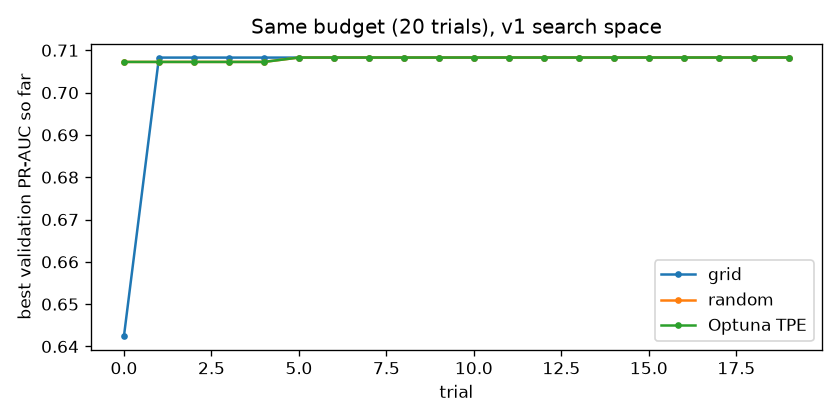

In [8]:
path = RESULTS / "search.csv"
if path.exists():
    display(pd.read_csv(path).round(4))
    display(Image(str(RESULTS / "search.png")))
else:
    print("Not run yet: python3 -m tuning.logistic_regression search")

**Reading** (`search.csv`, `search_trials.csv`).
- **The three methods end at the same score:** 0.7083 ± 0.013, ROC-AUC 0.889,
  Brier 0.111. Their best trials differ only in the 5th decimal.
- **All three get there fast:** the best-so-far reaches 0.7083 (4 decimals) at
  trial 1 for the grid (C = 100, L2) and at trial 5 for random and TPE.
- **TPE's first 10 trials are the same draws as the random search** (same seed:
  TPE starts with random trials), so the only difference is in trials 10-19.
  There TPE did what it is built for: 8 of its 10 guided trials used L2, and 8
  used C ≥ 0.5, i.e. the plateau. But there was nothing better left to find.
- **TPE at trial 16 finds C = 5.18, L2, no weights: exactly the v1 result**,
  because it uses the same sampler, seed and space as `tuning/tune.py`. So v1 is
  reproducible.
- **Lesson (the same as F36 for the forest):** when the validation curve is
  flat, the search method does not matter; a small grid is enough. A guided
  search pays off when many settings interact (LightGBM), not for one flat C.
- The run times (52-67 s) were measured while another job was running, so they
  are not compared here.

## 8. Findings

1. **No overfitting: the logistic regression underfits a little (bias).**
   Train 0.710, validation 0.708, gap 0.0014 (fold std ± 0.013). The flexible
   models reach 0.715-0.719: being linear costs about 0.01 PR-AUC.
2. **C hardly matters.** For L2 and L1 alike the curve is flat from C ≈ 0.3 to
   100 (0.708); only a strong penalty (C ≤ 0.03) changes anything, and it only
   underfits. Tuned v1 (C = 5.18) = default (C = 1): 0.7083 vs 0.7082.
3. **Lasso keeps almost everything on the plateau** (at C = 1 only 2 of 37
   columns are at 0 in all folds: occupation Never-worked, 8 people, and a
   duplicate column). Under a stronger penalty it switches off the rare
   categories first and keeps, in order, education, age, hours and marital
   status: the EDA signals. Elastic Net never beats L2.
4. **Class weights hurt the probabilities** (Brier 0.111 → 0.140) without
   helping the ranking: fixed at None, as for the random forest.
5. **One interaction passes the rule fixed in advance:** married × hours
   (+0.0016 PR-AUC, better in 5 of 5 folds); education × hours (+0.0003) and
   age × education (0.0000) do not.
6. **Grid, random and Optuna search find the same 0.7083** with 20 trials each:
   on a flat curve the method does not matter.
7. **Tuning v2** (C 0.01-100, L2, no class weights) finds C = 6.80 and the
   same scores as v1 to 4 decimals (0.7083, Brier 0.1113).

**Final logistic regression: tuned v2** (`tuning/results/v2/best_params.json`,
C = 6.80, L2, no class weights), equal to v1 and to the default within the
noise, with good probabilities and no recalibration (Brier 0.111). It stays
the transparent benchmark, about 0.007 below random forest v2 and 0.011 below
LightGBM v2. The married x hours interaction is not included (section 5).
Details: findings F37 and F40 in `docs/findings_log.md`.